--- Logistic Regression Performance ---
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

--- Random Forest Performance ---
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

--- Gradient Boosting Performance ---
              precision    recall  f1-score   support

           0       0.97      0.90      0.94        42
           1       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg    

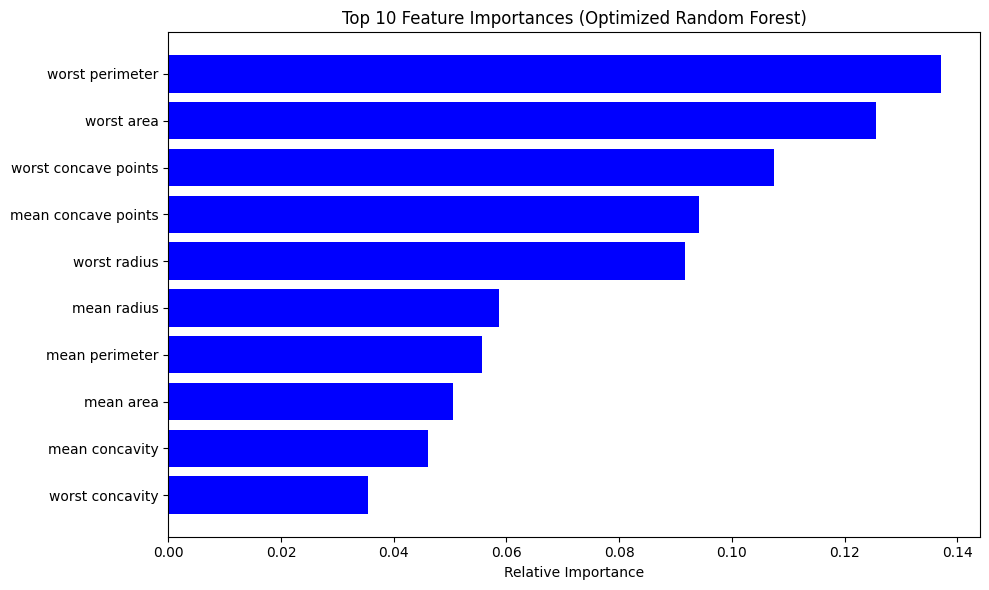

In [1]:
# Part A: Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Part B: Load Dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Part C: Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Part D: Feature Scaling (Needed for Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- 1. Baseline Model (Logistic Regression) ---
model_lr = LogisticRegression(max_iter=1000, random_state=42)
model_lr.fit(X_train_scaled, y_train)
y_pred_lr = model_lr.predict(X_test_scaled)

print("--- Logistic Regression Performance ---")
print(classification_report(y_test, y_pred_lr))

# --- 2. Random Forest Model ---
# Note: Random Forest typically doesn't strictly require scaling, 
# but can take unscaled data directly.
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("--- Random Forest Performance ---")
print(classification_report(y_test, y_pred_rf))

# --- 3. Gradient Boosting Model ---
gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)

print("--- Gradient Boosting Performance ---")
print(classification_report(y_test, y_pred_gb))

# --- Part H: Hyperparameter Tuning (GridSearchCV) ---
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7]
}
grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=5, scoring='f1')
grid.fit(X_train, y_train)

print("Best Parameters found via GridSearchCV:")
print(grid.best_params_)
print(f"Best Cross-Validation F1 Score: {grid.best_score_:.4f}")

# Evaluate tuned model on test set
best_rf = grid.best_estimator_
y_pred_best_rf = best_rf.predict(X_test)

# --- Part I & J: Model Comparison Dictionary ---
models = {
    "Logistic Regression": y_pred_lr,
    "Random Forest (Default)": y_pred_rf,
    "Gradient Boosting": y_pred_gb,
    "Random Forest (Tuned)": y_pred_best_rf
}

comparison_data = []
for name, preds in models.items():
    comparison_data.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "F1-Score": f1_score(y_test, preds)
    })

df_comparison = pd.DataFrame(comparison_data)
print("\n--- Final Model Comparison Table ---")
print(df_comparison.to_string(index=False))

# Optional (Advanced): Feature Importance Visualization for Best Random Forest
plt.figure(figsize=(10, 6))
importances = best_rf.feature_importances_
indices = np.argsort(importances)[-10:] # Top 10 features
plt.title("Top 10 Feature Importances (Optimized Random Forest)")
plt.barh(range(len(indices)), importances[indices], color='b', align='center')
plt.yticks(range(len(indices)), [X.columns[i] for i in indices])
plt.xlabel("Relative Importance")
plt.tight_layout()
plt.show()